# Marmousi: DIP Reparameterization + Tikhonov


In [1]:
from pathlib import Path
from collections import defaultdict
from functools import partial
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from tqdm.auto import tqdm
from IPython.display import display

from utils import wavelet_forward, calc_metrics
from inference_utils import get_impedance_cmap
from paper_plotting import section_figure_size, paper_section, paper_colorbar as add_colorbar
from inversion_utils import (
    wavelet_fitting, make_background_filter, initial_fn, forward_wavelet_fn,
)

from models.dip import UNet
from utils import gaussian_kernel, prepare_background



## 1. Device and Parameterization


In [2]:
ROOT = Path.cwd().resolve()
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(8)
if device.type == "cuda":
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cuda.matmul.allow_tf32 = False
print("Device:", device)


Device: cuda:3


## 2. Select Input Data


In [3]:
data_dir = ROOT / "data" / "marmousi" / "marmousi_2300x730"
output_dir = ROOT / "results" / "marmousi_dip_tikhonov" / data_dir.name
output_dir.mkdir(parents=True, exist_ok=True)

metadata = json.loads((data_dir / "section_metadata.json").read_text(encoding="utf-8"))
print("Input:", data_dir)
print("Output:", output_dir)


Input: /wzg3/home/hanlong/MyProject/2DGeoDiffInv/data/marmousi/marmousi_2300x730
Output: /wzg3/home/hanlong/MyProject/2DGeoDiffInv/results/marmousi_dip_tikhonov/marmousi_2300x730


## 3. Impedance Section and Observed Seismic Data


In [4]:
imp_min, imp_max = float(metadata["imp_min"]), float(metadata["imp_max"])
raw_image_denorm = torch.from_numpy(
    np.load(data_dir / "clean_section.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
raw_image = (raw_image_denorm - imp_min) / (imp_max - imp_min)
seis_slice = torch.from_numpy(
    np.load(data_dir / "seis_slice.npy", allow_pickle=False)).float()[None, None].to(device)
if raw_image.ndim != 3 or tuple(raw_image.shape[-2:]) != tuple(seis_slice.shape[-2:]):
    raise ValueError("Impedance and seismic data must be 2D sections with matching dimensions.")
seis_min, seis_max = seis_slice.min(), seis_slice.max()
seis_amplitude = float(seis_slice.abs().max())
if seis_amplitude <= 0:
    raise ValueError("The observed seismic amplitudes must not all be zero.")
seis = (seis_slice / seis_amplitude * 0.5 + 0.5).squeeze(0)

f0 = float(metadata.get("f0", 80.0))
dt = float(metadata.get("dt", metadata.get("seismic_generation", {}).get("dt", 0.0005)))
cmap = get_impedance_cmap("marmousi")
cmap2 = plt.get_cmap("seismic")
plot_min, plot_max = (3000.0, 11000.0)
aspect = 1
print("Shape:", tuple(raw_image.shape[-2:]), "| f0:", f0, "| dt:", dt)

# Compute article metrics using the true impedance range, separately from the inversion normalization range.
metric_data_range = float(raw_image_denorm.max() - raw_image_denorm.min())

# The following settings only format the article figures; they do not affect normalization, forward modeling, or metrics.
plot_options = dict(dataset="marmousi_regularization", wells=metadata.get("well_starts", ()),
                    well_width=int(metadata.get("well_width", 3)), dt=dt)


Shape: (2300, 730) | f0: 80.0 | dt: 0.0005


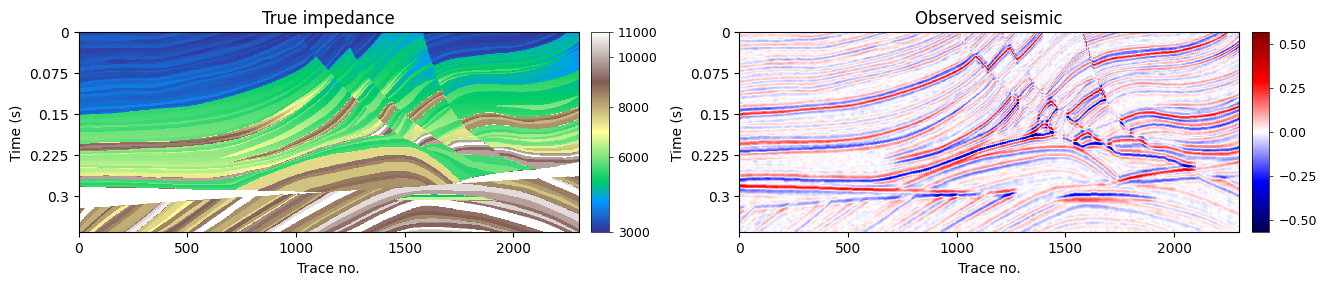

In [5]:
plt.figure(figsize=section_figure_size(raw_image.shape[-2:], dataset=plot_options["dataset"]))
plt.subplot(121)
plt.imshow(raw_image_denorm[0].cpu().T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("True impedance")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.subplot(122)
plt.imshow(seis_slice[0, 0].cpu().T, cmap=cmap2, vmin=-seis_amplitude,
           vmax=seis_amplitude, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=False,
              show_wells=True, **plot_options)
plt.title("Observed seismic")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 4. Well Logs and Masks


Well starts: [107, 270, 511, 1137, 1854, 2117]


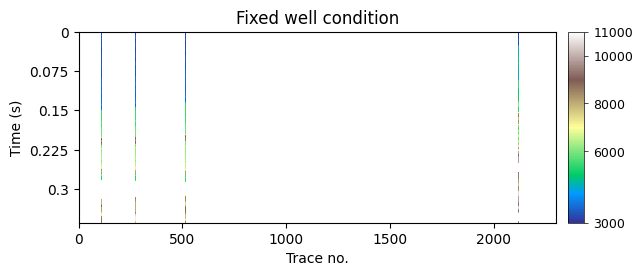

In [6]:
data_well_slice = torch.from_numpy(
    np.load(data_dir / "well_image.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
mask_well_slice = torch.from_numpy(
    np.load(data_dir / "well_mask.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
if data_well_slice.shape != raw_image.shape or mask_well_slice.shape != raw_image.shape:
    raise ValueError("Well logs, masks, and impedance must have matching dimensions.")
if mask_well_slice.sum() <= 0:
    raise ValueError("Wavelet estimation requires at least one valid well-log segment.")
if (data_well_slice * (1 - mask_well_slice)).any():
    raise ValueError("Well-log conditions must be zero outside the mask.")
well_images = data_well_slice.unsqueeze(0)
mask = mask_well_slice.unsqueeze(0)

columns = torch.where(mask[0, 0].any(dim=-1))[0].cpu().numpy()
dot = columns[np.r_[True, np.diff(columns) > 1]].tolist()
print("Well starts:", dot)
well_images_denorm = (well_images * 0.5 + 0.5) * (imp_max - imp_min) + imp_min
# Well overlays come from the actual input logs and masks and are used only for display.
plot_options.update(wells=dot,
                    well_values=well_images_denorm[0, 0].detach().cpu().numpy(),
                    well_mask=mask[0, 0].detach().cpu().numpy())
shown_wells = np.ma.masked_where(mask[0, 0].cpu().numpy().T == 0,
                                well_images_denorm[0, 0].cpu().numpy().T)
plt.figure(figsize=section_figure_size(raw_image.shape[-2:], cols=1, dataset=plot_options["dataset"]))
plt.imshow(shown_wells, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("Fixed well condition")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 5. Initial Low-Frequency Model


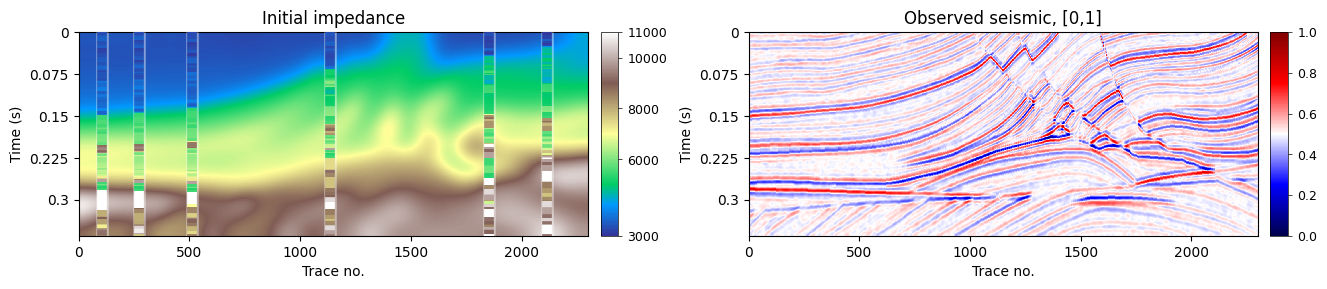

In [7]:
ks = int(metadata["initial_model_kernel"])
smoothed = torch.from_numpy(
    np.load(data_dir / "initial_model.npy", allow_pickle=False)).float().unsqueeze(0).to(device)
if smoothed.shape != raw_image.shape:
    raise ValueError("The initial model and impedance must have matching dimensions.")
if metadata.get("initial_model_scale") != "normalized_0_1":
    smoothed = (smoothed - imp_min) / (imp_max - imp_min)
smoothed_denorm = smoothed * (imp_max - imp_min) + imp_min

plt.figure(figsize=section_figure_size(raw_image.shape[-2:], dataset=plot_options["dataset"]))
plt.subplot(121)
plt.imshow(smoothed_denorm[0].cpu().T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=True, **plot_options)
plt.title("Initial impedance")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.subplot(122)
plt.imshow(seis[0].cpu().T, cmap=cmap2, vmin=0, vmax=1, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=False,
              show_wells=True, **plot_options)
plt.title("Observed seismic, [0,1]")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.show()


## 6. Normalization, Background Operator, and Evaluation Range


In [8]:
# Set background_implementation to "conv2d" to use the original convolution without changing the kernel or inversion parameters.
background_implementation = "fft"  # The "conv2d" option changes only the background-smoothing implementation.
image_shape = (1, 1, *raw_image.shape[-2:])
smoothed_norm = (smoothed.unsqueeze(0) - 0.5) / 0.5
cond_image = (seis.unsqueeze(0) - 0.5) / 0.5
# Cache background smoothing with the existing FFT implementation, using the same NumPy Gaussian kernel and reflection boundaries.
background_kernel = torch.from_numpy(gaussian_kernel(ks, ks / 7)).float().to(device)[None, None]
background_filter = prepare_background(
    {"kernel": background_kernel, "shape": tuple(smoothed_norm.shape[-2:])},
    implementation=background_implementation)

f0_ = torch.tensor([f0])
dt_ = torch.tensor([dt])
print("Image shape:", image_shape, "| Normalized seismic:", tuple(cond_image.shape))


Image shape: (1, 1, 2300, 730) | Normalized seismic: (1, 1, 2300, 730)


## 7. Wavelet Estimation


In [9]:
window = (seis.shape[-2], max(1, seis.shape[-1] // 32))
int_size = (seis.shape[-2], 8)
wavelet_iterations = 80
wavelet_lr = 0.02
wavelet_amplitude_scale = 1.0
wavelet_scale = {
    "seismic": {"match": 0, "tv_x": 0, "tv_z": 0, "tv_t": 0, "sidelobe_loss": 0},
    "well": {"match": 10, "tv_x": 0, "tv_z": 500, "tv_t": 0, "sidelobe_loss": 0},
}
wavelet_mat, norm_dic, norm_dic_seis, seis_pred_ori_return = wavelet_fitting(
    f0_[0:1], dt_[0:1], 10 / f0_[0:1], torch.tensor([1]),
    torch.ones_like(raw_image).unsqueeze(0), cond_image,
    data_well_slice.unsqueeze(0), wavelet_iterations,
    seis_min, seis_max, imp_min, imp_max,
    int_size=int_size, mask=mask, mode="ricker", method="opt", optimizer="Adam",
    lr=wavelet_lr, window=window, scale=wavelet_scale, amplitude_scale=wavelet_amplitude_scale)
window_new = int_size
np.save(output_dir / "estimated_wavelet_mat.npy", wavelet_mat.cpu().numpy())
print("Estimated wavelet shape:", tuple(wavelet_mat.shape))
print("Final well match:", norm_dic["match"][-1])


  0%|          | 0/80 [00:00<?, ?it/s]

Estimated wavelet shape: (1, 92, 999)
Final well match: 671.3123779296875


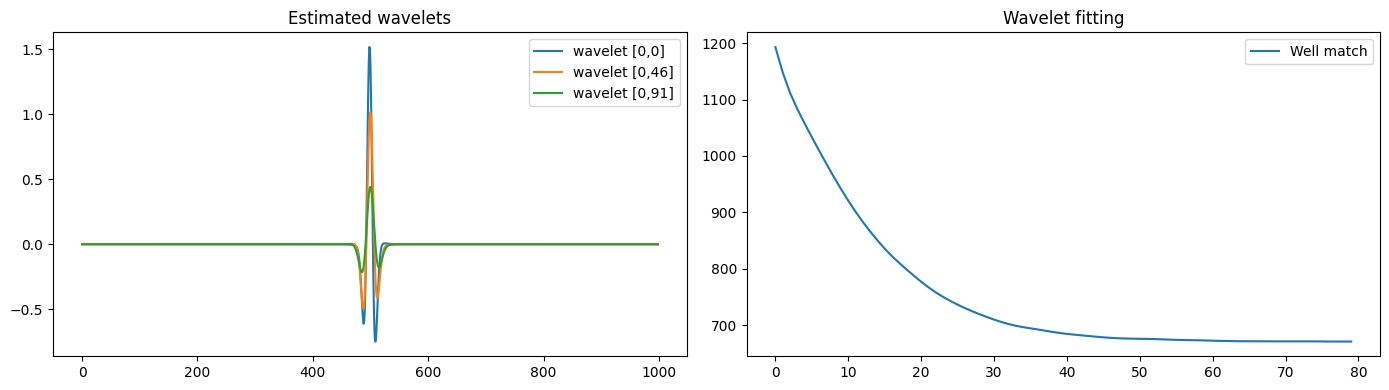

Estimated/saved wavelet difference RMSE: 7.97639529537264e-07


In [10]:
plt.figure(figsize=(14, 4))
plt.subplot(121)
for j in sorted(set([0, wavelet_mat.shape[1] // 2, wavelet_mat.shape[1] - 1])):
    plt.plot(wavelet_mat[0, j].cpu(), label=f"wavelet [0,{j}]")
plt.title("Estimated wavelets")
plt.legend()
plt.subplot(122)
plt.plot(norm_dic["match"], label="Well match")
plt.title("Wavelet fitting")
plt.legend()
plt.tight_layout()
plt.show()

reference_wavelet_path = data_dir / "estimated_wavelet_mat.npy"
if reference_wavelet_path.is_file():
    reference_wavelet = torch.from_numpy(np.load(reference_wavelet_path, allow_pickle=False)).float()
    if reference_wavelet.shape == wavelet_mat.shape:
        wavelet_difference = float((wavelet_mat.cpu() - reference_wavelet).square().mean().sqrt())
        print("Estimated/saved wavelet difference RMSE:", wavelet_difference)


## 8. Forward Modeling at Well Locations


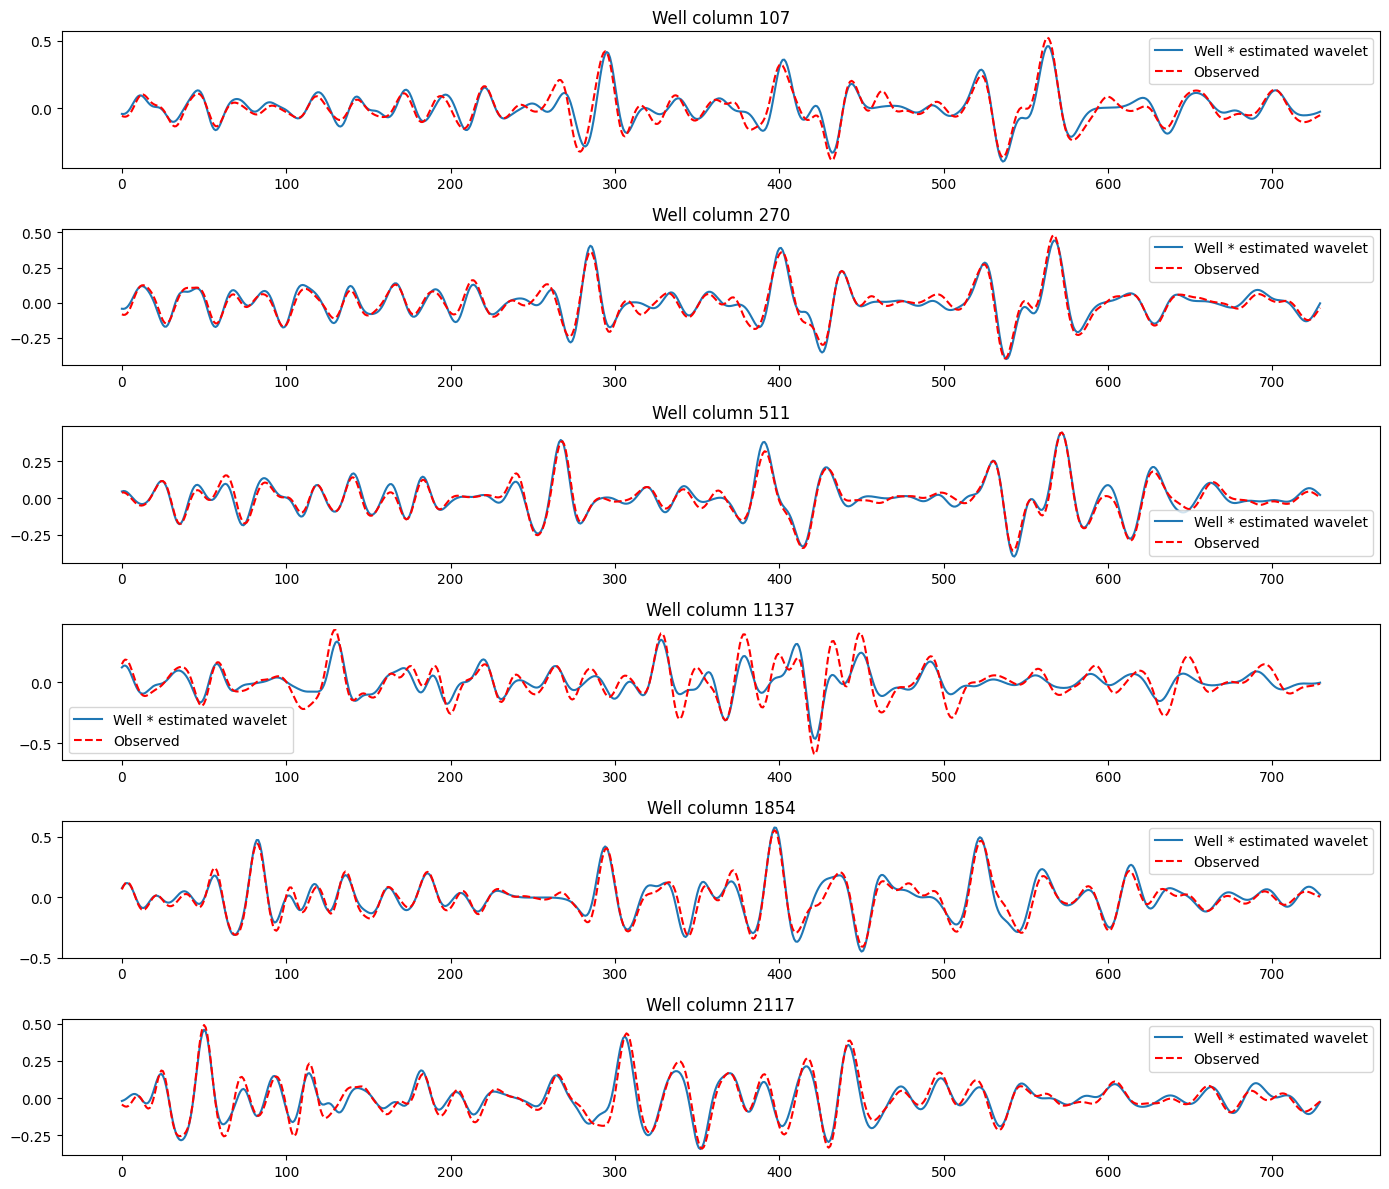

In [11]:
with torch.no_grad():
    seis_forward2 = wavelet_forward(
        wavelet_mat, data_well_slice.unsqueeze(0), window_new,
        seis_min, seis_max, imp_min, imp_max)
plt.figure(figsize=(14, max(3, 2 * len(dot))))
for j, trace in enumerate(dot):
    plt.subplot(len(dot), 1, j + 1)
    plt.plot(seis_forward2[0, 0, trace].cpu(), label="Well * estimated wavelet")
    plt.plot(cond_image[0, 0, trace].cpu(), "r--", label="Observed")
    plt.title(f"Well column {trace}")
    plt.legend()
plt.tight_layout()
plt.show()


## 9. Spatial Regularization and Data Fitting


In [12]:
def batch_tv(data):
    dims = data.shape
    score = 0
    if len(dims) == 3:
        for i in range(data.shape[0]):
            vol = data[i]       
            diff1 = vol[1:] - vol[:-1]
            diff2 = vol[:, 1:] - vol[:, :-1]
            res1 = diff1.abs().sum()
            res2 = diff2.abs().sum()
            # res1 = torch.linalg.norm(diff1, ord=1)
            # res2 = torch.linalg.norm(diff2, ord=1)
            score += res1 + 1 * res2 

    else:
        raise ValueError("Unsupported data dimensionality. Expected 3 or 4 dimensions, got {}.".format(data.dim()))
    return score

def batch_tikhonov(data):
    dims = data.shape
    score = 0
    if len(dims) == 3:
        for i in range(data.shape[0]):
            vol = data[i]       
            diff1 = vol[1:] - vol[:-1]
            diff2 = vol[:, 1:] - vol[:, :-1]
            res1 = (diff1**2).sum()
            res2 = (diff2**2).sum()
            # res1 = torch.linalg.norm(diff1, ord=1)
            # res2 = torch.linalg.norm(diff2, ord=1)
            score += res1 + 1 * res2 

    else:
        raise ValueError("Unsupported data dimensionality. Expected 3 or 4 dimensions, got {}.".format(data.dim()))
    return score


In [13]:
def data_fitting(image_dif, image_denoise, net, opti_old, num_iterations, lr,
                 forward_fns, scale, wavelet_mat, regular):
    image_init = image_denoise.clone().detach()
    net.train()
    if regular not in ("tv", "tikhonov"):
        raise ValueError("regular must be either tv or tikhonov.")
    regular_fn = batch_tv if regular == "tv" else batch_tikhonov

    # Keep parameters across rounds, recreate the optimizer each round, and do not carry Adam moments between rounds.
    for param_group in opti_old.param_groups:
        param_group["lr"] = float(lr)
    opti = type(opti_old)(opti_old.param_groups, **opti_old.defaults)

    norm_dics = defaultdict(list)
    for _ in range(num_iterations):
        image = image_init + net(image_dif).reshape_as(image_init)
        opti.zero_grad()
        values = {
            "forward_wavelet": forward_fns["forward_wavelet"](image=image, wavelet_mat=wavelet_mat),
            regular: regular_fn(image[:, 0]),
            "initial": forward_fns["initial"](image=image),
            "data_keep": torch.linalg.norm(image - image_init) ** 2,
        }
        norm = sum(scale[key] * value for key, value in values.items())
        norm.backward()
        opti.step()
        for key, value in values.items():
            norm_dics[key].append(float(value.detach()))

    with torch.no_grad():
        net.eval()
        image_fit = (image_init + net(image_dif).reshape_as(image_init)).clamp(-1, 1)
    return image_fit.detach(), norm_dics


## 10. Inversion Parameters


In [21]:
num_runs = 1
seed_start = 46
plot_seed = seed_start
epochs = 200
begin_ratio = 0.9
begin_epoch = int(epochs * begin_ratio)
num_iterations = 10
skip_fitting_rounds = 2
regular = "tikhonov"
lr_start = 0.0001
lr_end = 0.001
seismic_weight = 1
initial_weight = 1
regularization_weight = 2.0
datakeep_weight = 0.0
plot_interval = max(1, begin_epoch // 5)

if num_runs < 1 or begin_epoch <= skip_fitting_rounds:
    raise ValueError("Check the number of runs and outer rounds.")
print("Actual outer rounds:", begin_epoch, "| Data-fitting outer rounds:", begin_epoch - skip_fitting_rounds)



实际外循环: 180 | 数据拟合外循环: 178


## 11. Inversion Process


参数或执行顺序已改变，重新计算反演结果。


  0%|          | 0/180 [00:00<?, ?it/s]

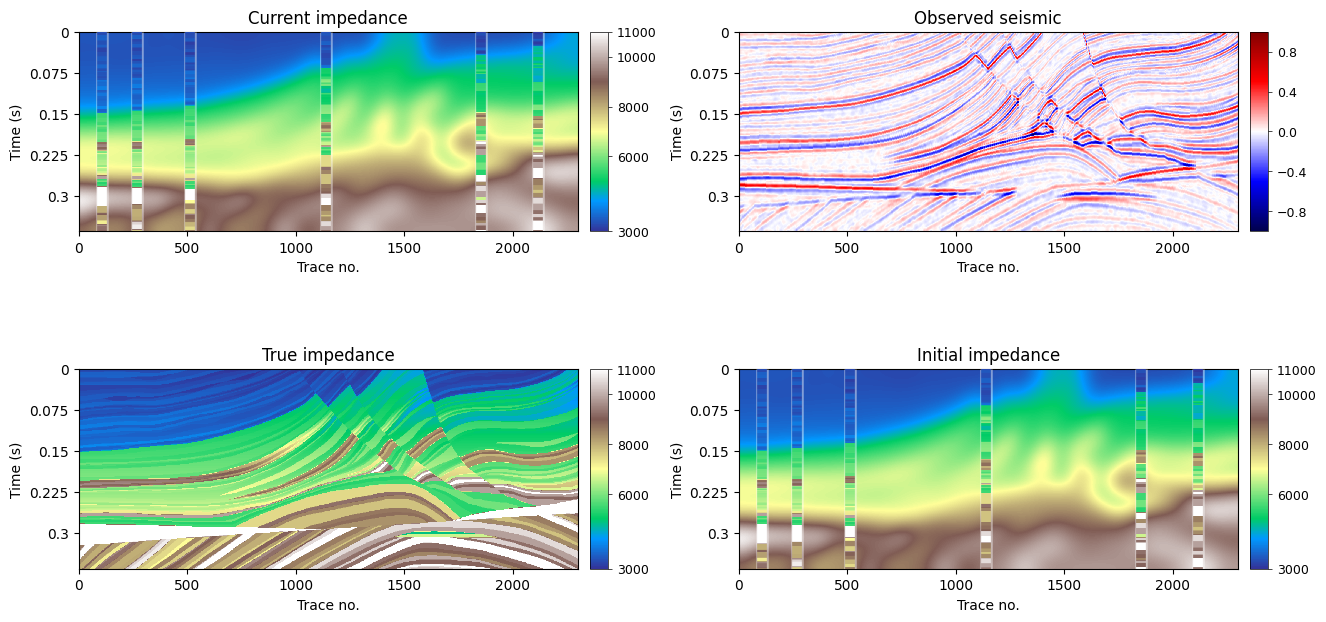

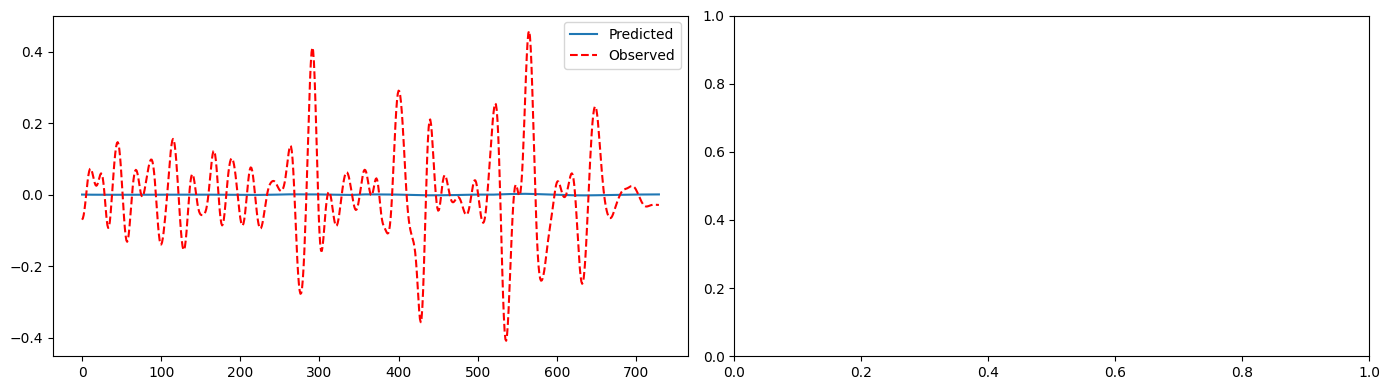

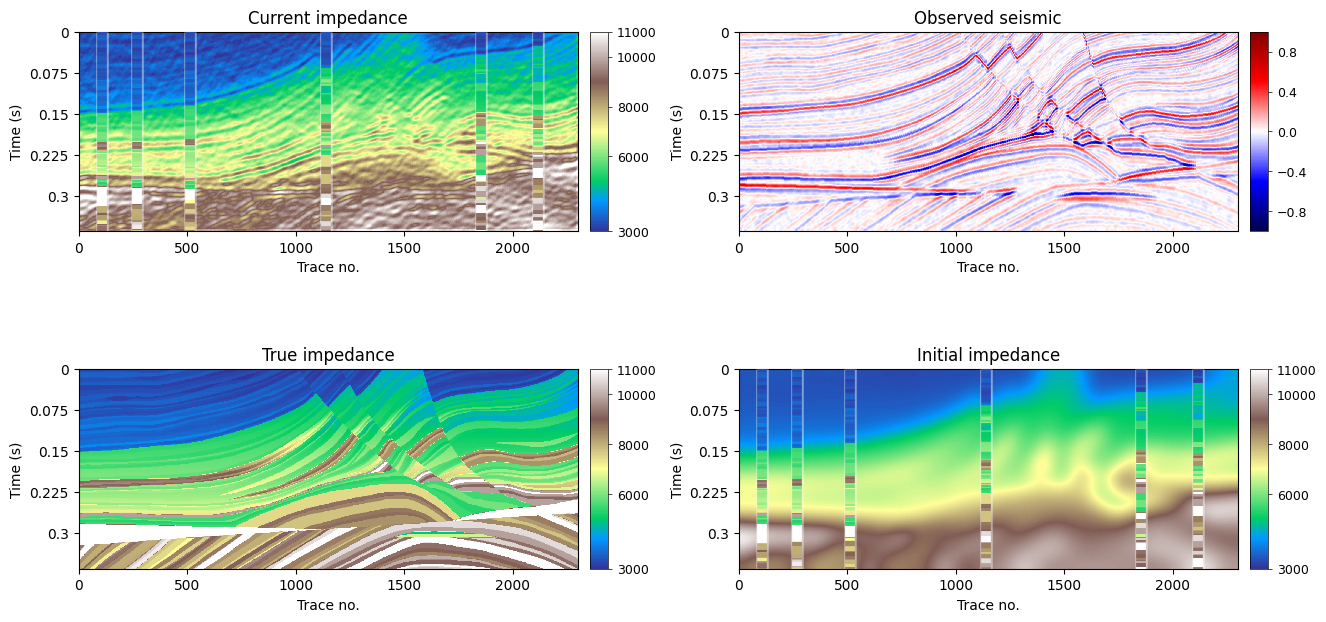

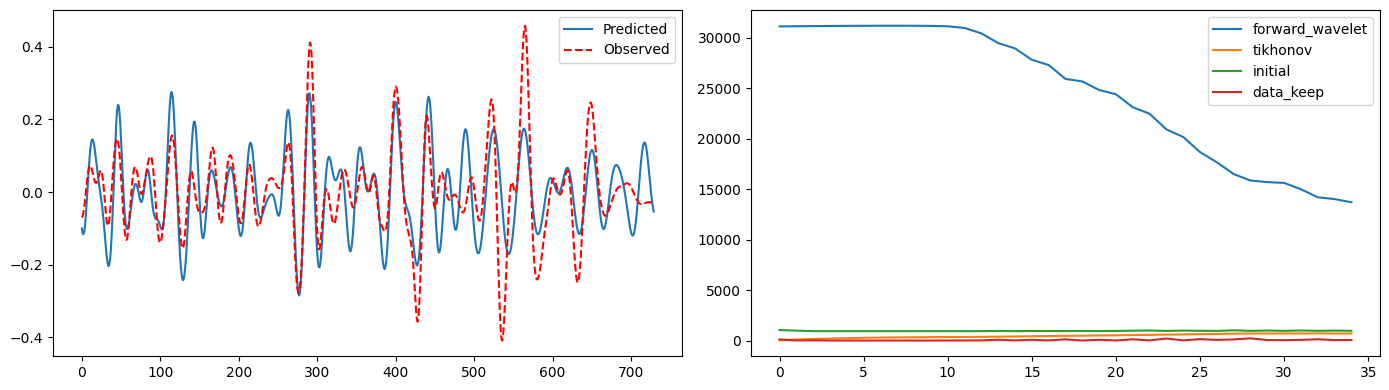

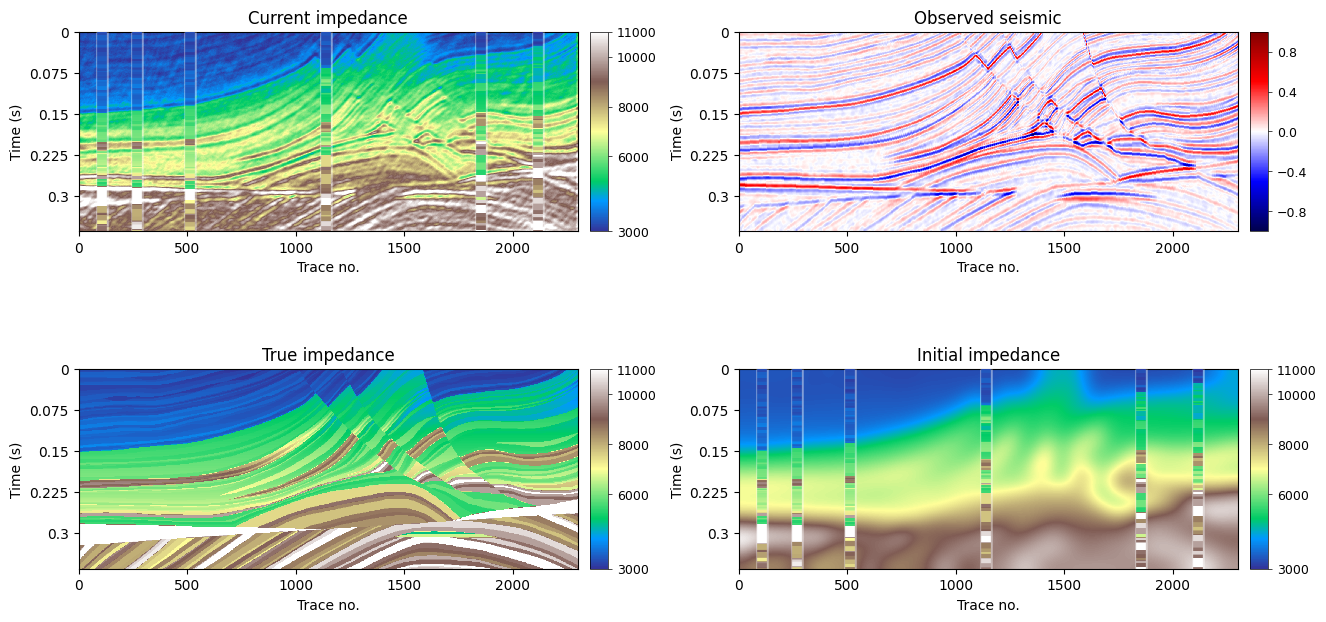

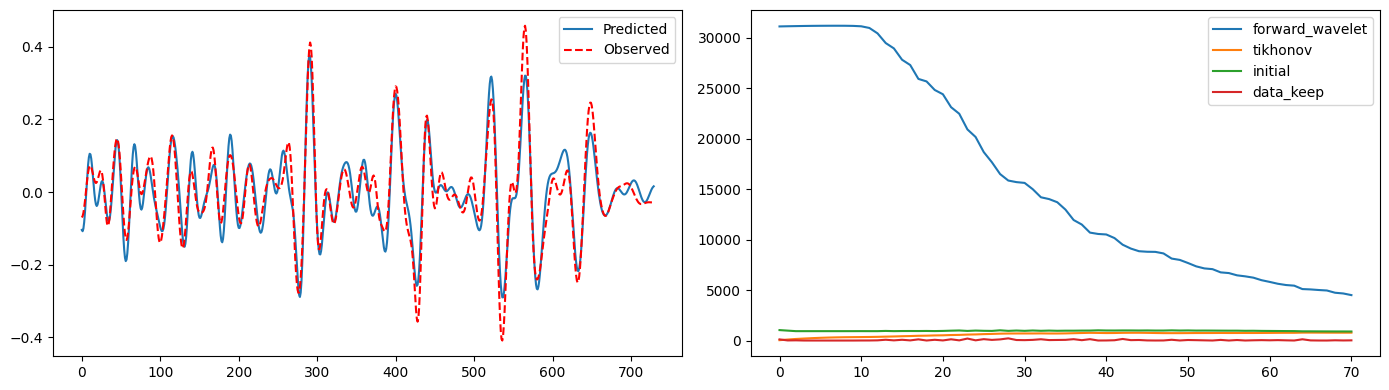

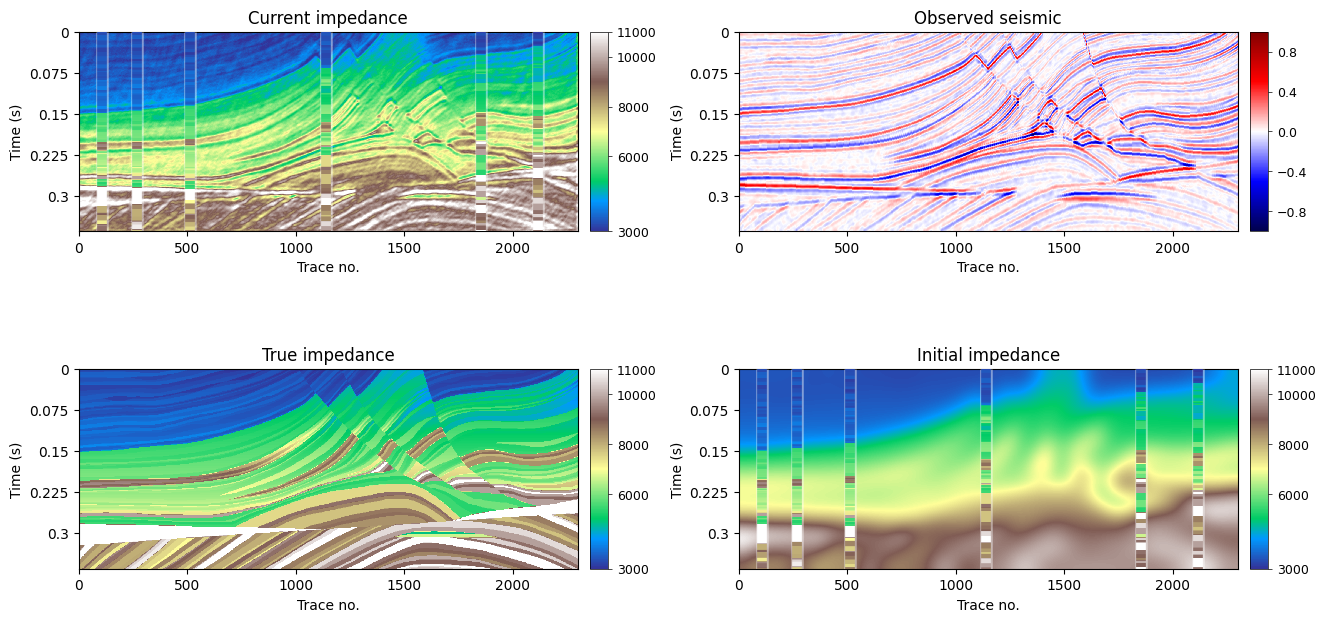

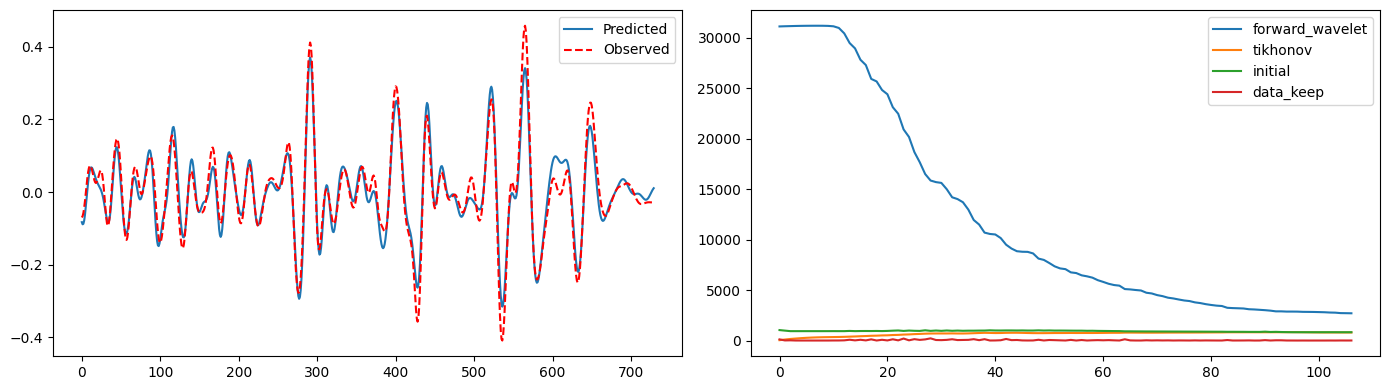

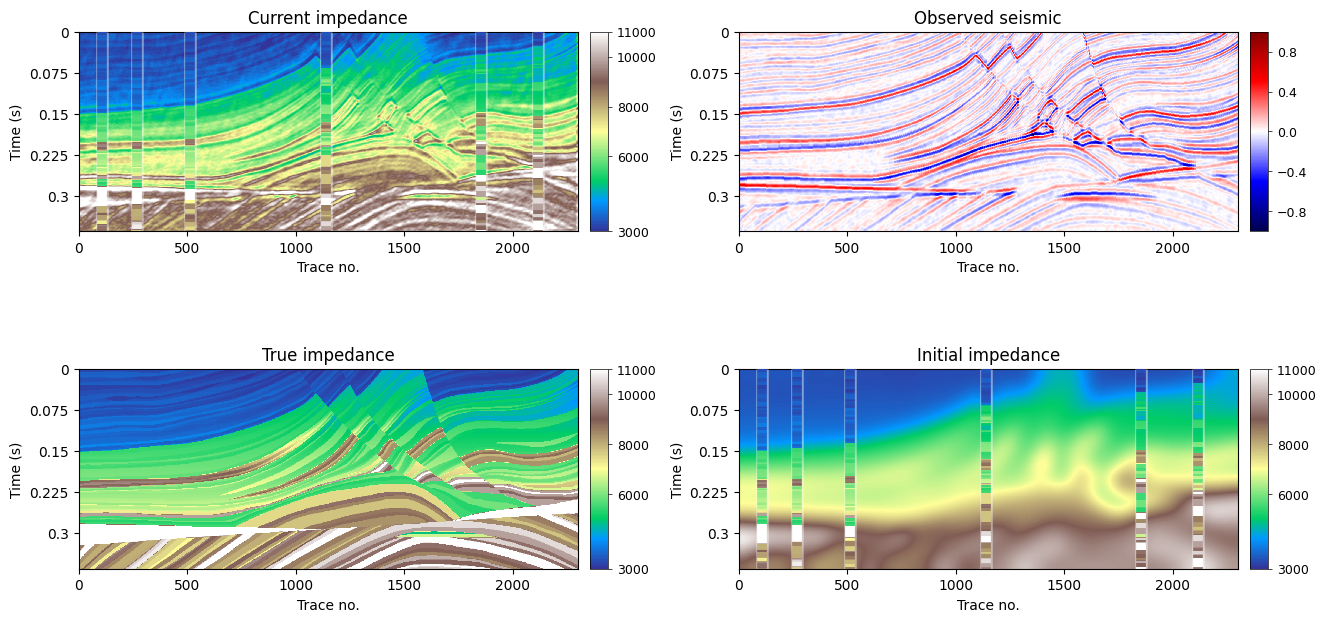

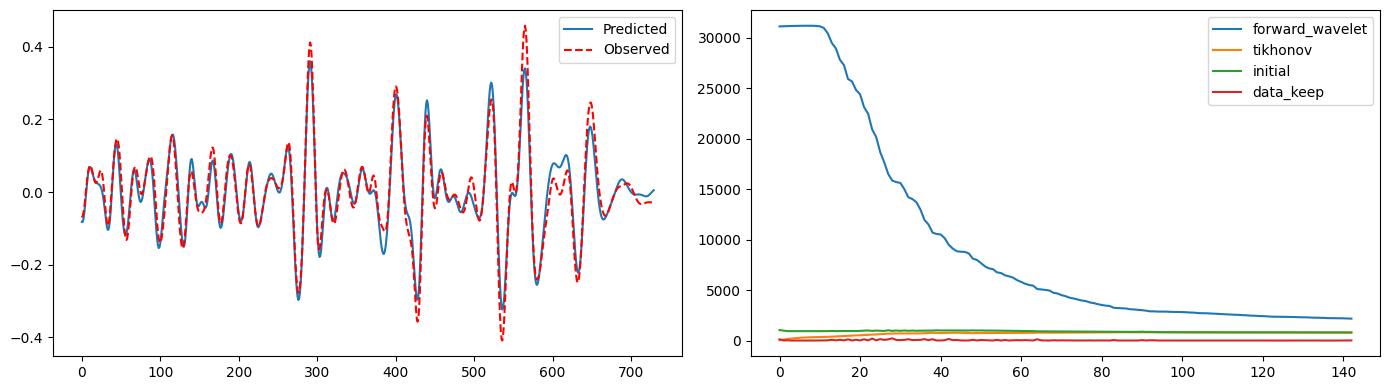

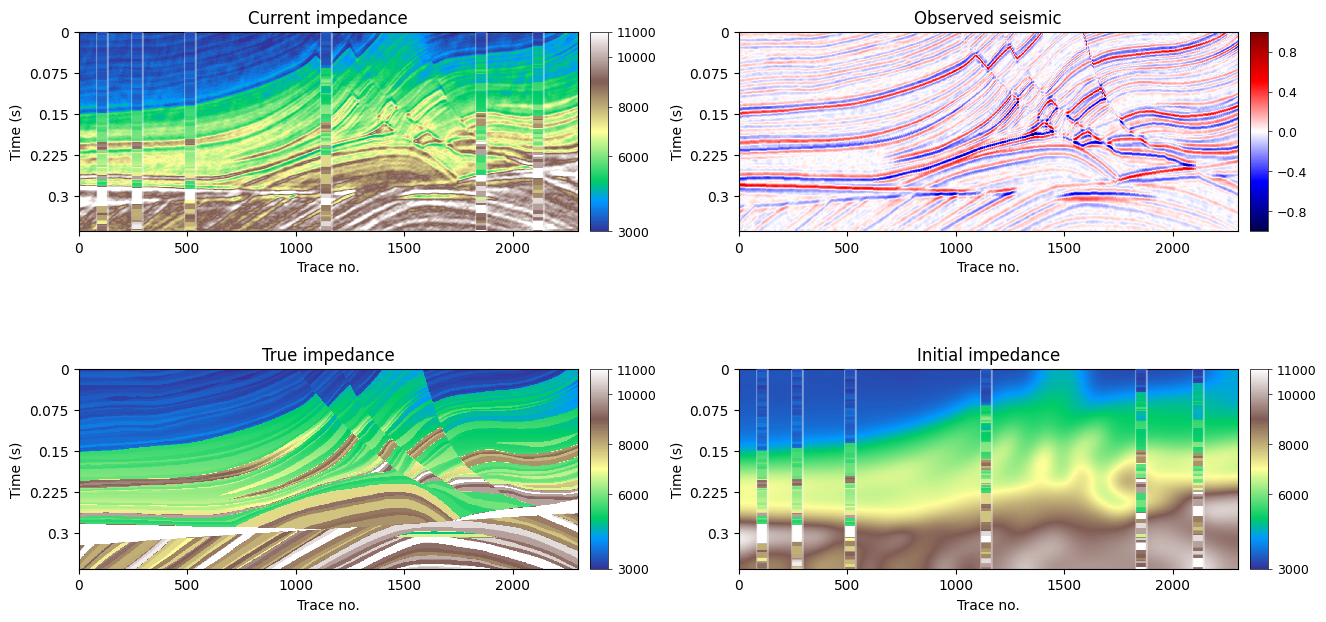

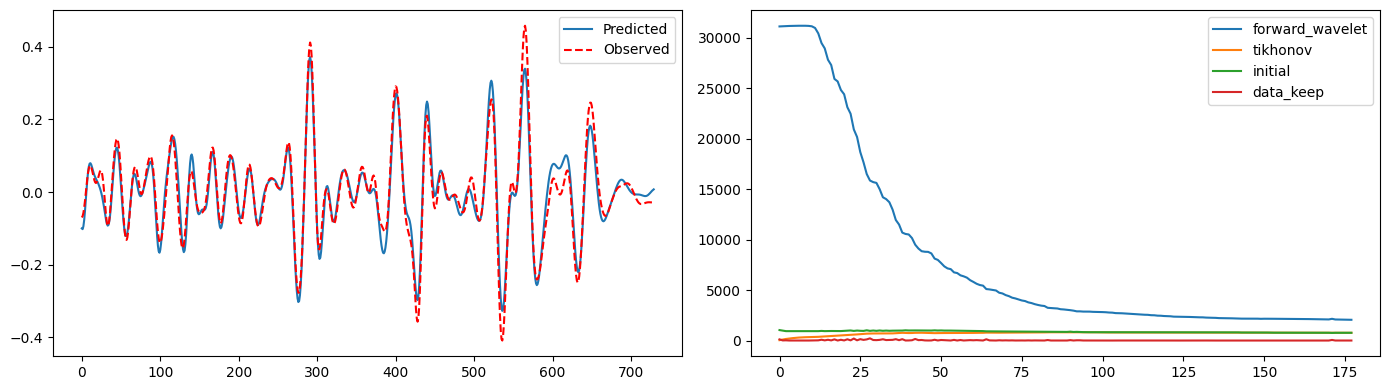

Seed: 46 | Metrics: {'RMSE': 880.0912475585938, 'PSNR': 20.316768087418314, 'SSIM': 0.7967025637626648, 'MAE': 615.408203125, 'CorrCoef': 0.9360214630885596}


In [22]:
results = []
run_records = []
for iter in range(num_runs):
    seed = seed_start + iter
    torch.manual_seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)

    image_fit = smoothed_norm.clone()
    image_denoise = smoothed_norm.clone()
    lr_scheduler = np.linspace(lr_start, lr_end, begin_epoch)
    forward_wavelet_scheduler = np.linspace(seismic_weight, seismic_weight, begin_epoch)
    initial_scheduler = np.linspace(initial_weight, initial_weight, begin_epoch)
    datakeep_scheduler = np.linspace(datakeep_weight, datakeep_weight, begin_epoch)
    tv_scheduler = np.linspace(regularization_weight, regularization_weight, begin_epoch)

    initial_func = partial(initial_fn, initial_image=smoothed_norm, background_filter=background_filter)
    forward_wavelet_func = partial(
        forward_wavelet_fn, cond_image=cond_image.detach(), window=window_new,
        imp_min=imp_min, imp_max=imp_max, seis_min=seis_min, seis_max=seis_max)

    net = UNet(n_channels=1, n_classes=1, channel_list=[16, 32, 64, 128]).to(device)
    image4upgrade = torch.randn(image_shape).to(device)
    opti = torch.optim.Adam(list(net.parameters()), lr=lr_scheduler[0])

    norm_dics = defaultdict(list)
    started = time.perf_counter()
    for i, epoch in tqdm(enumerate(range(begin_epoch, 0, -1)), total=begin_epoch):
        if i >= skip_fitting_rounds:
            image_fit, norm_dic = data_fitting(
                image4upgrade, image_denoise, net=net, opti_old=opti,
                num_iterations=num_iterations, lr=lr_scheduler[i],
                forward_fns={"forward_wavelet": forward_wavelet_func, "initial": initial_func},
                scale={"forward_wavelet": forward_wavelet_scheduler[i],
                       regular: tv_scheduler[i], "initial": initial_scheduler[i],
                       "data_keep": datakeep_scheduler[i]},
                wavelet_mat=wavelet_mat, regular=regular)
            image_fit = image_fit.clone().detach()
            for key, value in norm_dic.items():
                norm_dics[key].extend(value[-1:])
        image_denoise = image_fit

        if seed == plot_seed and plot_interval and (i % plot_interval == 0 or i == begin_epoch - 1):
            with torch.no_grad():
                model_output_denorm = (image_denoise * 0.5 + 0.5) * (imp_max - imp_min) + imp_min
                seis_forward = wavelet_forward(
                    wavelet_mat, image_denoise, window_new, seis_min, seis_max, imp_min, imp_max)
            plt.figure(figsize=section_figure_size(raw_image.shape[-2:], rows=2, cols=2, dataset=plot_options["dataset"]))
            for panel, array, title, colors, lo, hi in [
                (1, model_output_denorm[0, 0], "Current impedance", cmap, plot_min, plot_max),
                (2, cond_image[0, 0], "Observed seismic", cmap2, -1, 1),
                (3, raw_image_denorm[0], "True impedance", cmap, plot_min, plot_max),
                (4, (smoothed_norm[0, 0] * 0.5 + 0.5) * (imp_max - imp_min) + imp_min,
                 "Initial impedance", cmap, plot_min, plot_max)]:
                plt.subplot(2, 2, panel)
                plt.imshow(array.cpu().T, cmap=colors, vmin=lo, vmax=hi, aspect=aspect)
                paper_section(plt.gca(), plt.gci(), impedance=colors is cmap,
                              show_wells=title != "True impedance", **plot_options)
                plt.title(title)
                add_colorbar(plt.gcf(), plt.gci(), plt.gca())
            plt.tight_layout()
            plt.show()

            plt.figure(figsize=(14, 4))
            plt.subplot(121)
            trace = min(200, seis.shape[-2] - 1)
            plt.plot(seis_forward[0, 0, trace].cpu(), label="Predicted")
            plt.plot(cond_image[0, 0, trace].cpu(), "r--", label="Observed")
            plt.legend()
            plt.subplot(122)
            for key, value in norm_dics.items():
                plt.plot(value, label=key)
            if norm_dics:
                plt.legend()
            plt.tight_layout()
            plt.show()

    image = (image_denoise * 0.5 + 0.5).clamp(0, 1)
    results.append(image.detach().cpu())
    physical = image.cpu()[0, 0] * (imp_max - imp_min) + imp_min
    metrics = calc_metrics(physical, raw_image_denorm[0].cpu(), metric_data_range)
    record = dict(seed=seed, metrics=metrics, norm_dics=dict(norm_dics),
                  elapsed_seconds=time.perf_counter() - started)
    run_records.append(record)
    np.save(output_dir / f"seed_{seed}.npy", physical.numpy())
    (output_dir / f"seed_{seed}.json").write_text(
        json.dumps(record, indent=2) + "\n", encoding="utf-8")
    print("Seed:", seed, "| Metrics:", metrics)
    del image4upgrade, net, opti


## 12. Ensemble Evaluation, Plotting, and Saving


/tmp/ipykernel_1020483/3471337421.py:5: DeprecationWarning: In future, it will be an error for 'np.bool' scalars to be interpreted as an index
  pcc_finite = torch.tensor([np.isfinite(r["metrics"]["CorrCoef"]) for r in run_records])


,seed,retained,RMSE,PSNR,SSIM,MAE,CorrCoef
0,46,True,880.091248,20.316768,0.796703,615.408203,0.936021


Mean individual-run metrics (retained): {'RMSE': 880.0912475585938, 'MAE': 615.408203125, 'SSIM': 0.7967025637626648, 'CorrCoef': 0.9360214630885596}
Mean model: {'RMSE': 880.0912475585938, 'PSNR': 20.316768087418314, 'SSIM': 0.7967025637626648, 'MAE': 615.408203125, 'CorrCoef': 0.9360214630885596}


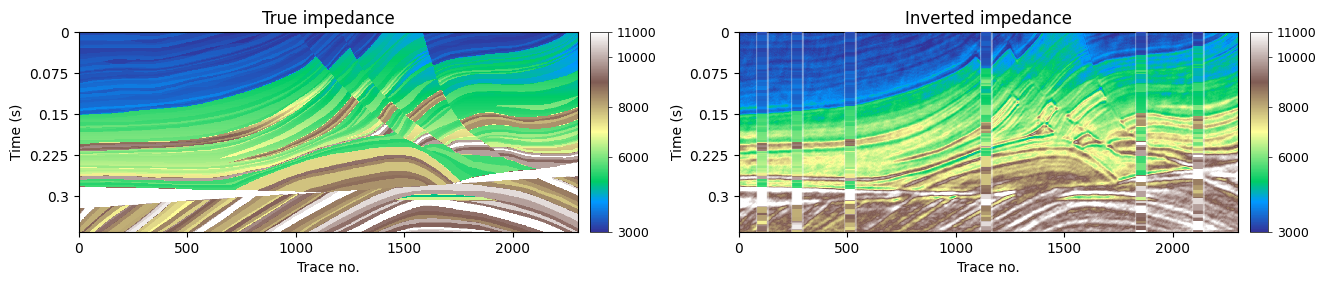

In [23]:
filt_results = torch.cat(results, dim=0) * (imp_max - imp_min) + imp_min
# Exclude mathematically degenerate models, then apply the original spatial-standard-deviation filter centered at the mean with a +/-20% range.
flat_results = filt_results.flatten(1)
spatial_range = flat_results.max(dim=1).values - flat_results.min(dim=1).values
pcc_finite = torch.tensor([np.isfinite(r["metrics"]["CorrCoef"]) for r in run_records])
valid = (spatial_range > 0) & pcc_finite
for record, span, finite_pcc in zip(run_records, spatial_range, pcc_finite):
    if float(span) == 0 or not bool(finite_pcc):
        reason = "Zero spatial range" if float(span) == 0 else "PCC is nonfinite"
        print("Excluded degenerate seed:", record["seed"], "|", reason)
if not valid.any():
    raise RuntimeError("All models are mathematically degenerate. Raw results are retained and ensemble evaluation is stopped.")
retained = valid.clone()
if int(valid.sum()) > 1:
    spatial_std = flat_results.std(dim=1)
    std_center = spatial_std[valid].mean()
    retained = valid & (spatial_std > std_center * 0.8) & (spatial_std < std_center * 1.2)
    if not retained.any():
        raise RuntimeError("The original spatial-standard-deviation filter retained no valid models.")
selected = filt_results[retained]
image = selected.mean(0, keepdim=True)
image_std = selected.std(0, correction=1) if len(selected) > 1 else torch.zeros_like(selected[0])
evaluation = calc_metrics(image[0, 0], raw_image_denorm[0].cpu(), metric_data_range)
table = pd.DataFrame([dict(seed=r["seed"], **r["metrics"]) for r in run_records])
table.insert(1, "retained", retained.numpy())
retained_table = table.loc[retained.numpy()]
independent_mean = {
    key: float(retained_table[key].mean()) for key in ["RMSE", "MAE", "SSIM", "CorrCoef"]}
display(table)
print("Mean individual-run metrics (retained):", independent_mean)
print("Mean model:", evaluation)
summary = dict(ensemble=evaluation, independent_mean=independent_mean, seeds=[r["seed"] for r in run_records],
               retained_seeds=[r["seed"] for r, keep in zip(run_records, retained) if keep])
(output_dir / "metrics_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
np.save(output_dir / "ensemble_mean.npy", image[0, 0].numpy())
np.save(output_dir / "ensemble_std.npy", image_std[0].numpy())
table.to_csv(
    output_dir / "metrics_per_run.csv", index=False)

plt.figure(figsize=section_figure_size(raw_image.shape[-2:], dataset=plot_options["dataset"]))
plt.subplot(121)
plt.imshow(raw_image_denorm[0].cpu().T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=False, **plot_options)
plt.title("True impedance")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.subplot(122)
plt.imshow(image[0, 0].T, cmap=cmap, vmin=plot_min, vmax=plot_max, aspect=aspect)
paper_section(plt.gca(), plt.gci(), impedance=True,
              show_wells=True, **plot_options)
plt.title("Inverted impedance" if num_runs == 1 else "Mean inversion")
add_colorbar(plt.gcf(), plt.gci(), plt.gca())
plt.tight_layout()
plt.savefig(output_dir / "inversion_result.png", dpi=160, bbox_inches="tight")
plt.show()
